## Step 1:
Load the data and import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

titanic = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
print(titanic.shape)
titanic.head()


(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 2:
Shows information about each column (info()) and how many empty values (Null) the data has

In [ ]:
# Run the info() function on the titanic data to get information about each column and to see the data type of each column
titanic.info()
print()
print("missing values per column")
print(titanic.isnull().sum())  # checks whether each column has nulls and prints how many ( sum() )


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

missing values per column
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked

## Step 3:
Statistics with a few charts

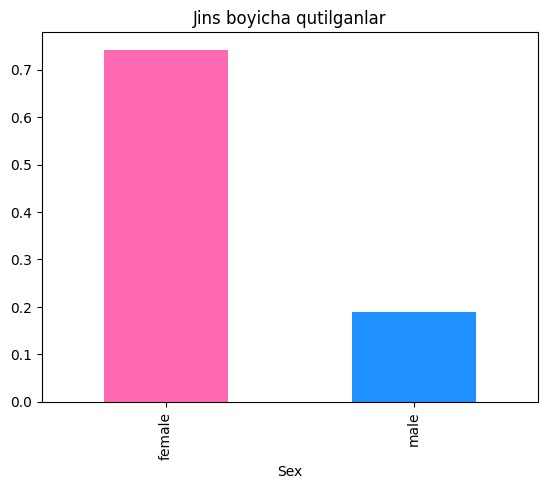

In [ ]:
titanic.groupby("Sex")["Survived"].mean().plot(kind="bar", color=["hotpink", "dodgerblue"]) # survival rate by sex, drawn as a bar chart with chosen colors
plt.title("Survival by sex")
plt.show()

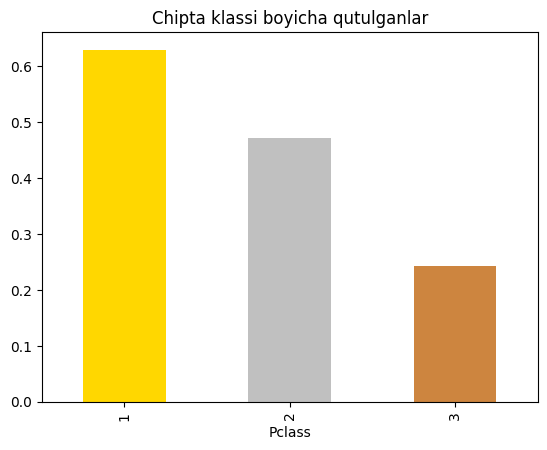

In [ ]:
titanic.groupby("Pclass")["Survived"].mean().plot(kind="bar", color=["gold", "silver", "peru"]) # survival rate by passenger class as a bar chart
plt.title("Survival by ticket class")
plt.show()

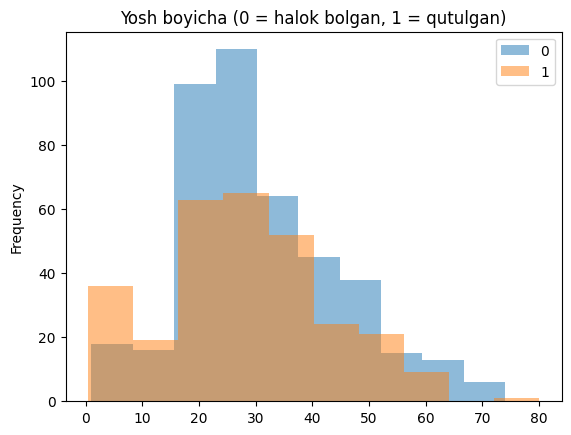

In [ ]:
titanic.groupby("Survived")["Age"].plot(kind="hist", alpha=0.5, legend=True) # age distribution of survivors vs. non-survivors
plt.title("By age (0 = died, 1 = survived)")
plt.show()


## Step 4:
Unneeded columns are dropped

In [ ]:
titanic = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"]) # drop the unneeded columns
titanic.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## Step 5: Cleaning

The computer doesn't understand empty cells and words, so we fix them

In [ ]:
# fill the missing ages with the median age
titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())

# fill the 2 missing ports with the most common port
titanic["Embarked"] = titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])

# convert words to numbers: male = 0, female = 1
titanic["Sex"] = titanic["Sex"].map({"male": 0, "female": 1})
titanic = pd.get_dummies(titanic, columns=["Embarked"], drop_first=True, dtype=int) # we'll explain this when we get here

print("Remaining missing values:", titanic.isnull().sum().sum()) # should be 0
titanic.head() # first five rows of the data

Remaining missing values: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


## Step 6: Train the model

We split the data in two

- Train (80%): the model learns from this
- Test (20%): the model never sees this, it is its exam

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
X = titanic.drop(columns = "Survived")
y = titanic["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

print("Accuracy: ", model.score(X_test, y_test))

print("Training score: ", round(model.score(X_train, y_train), 3))
print("Test score: ", round(model.score(X_test, y_test), 3))


Accuracy:  0.8100558659217877
Training score:  0.801
Test score:  0.81


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
predictions = model.predict(X_test)

correct = (predictions == y_test).sum()
wrong = (predictions != y_test).sum()

print("Correct answers:", correct)
print("Wrong answers:", wrong)

Correct answers: 145
Wrong answers: 34


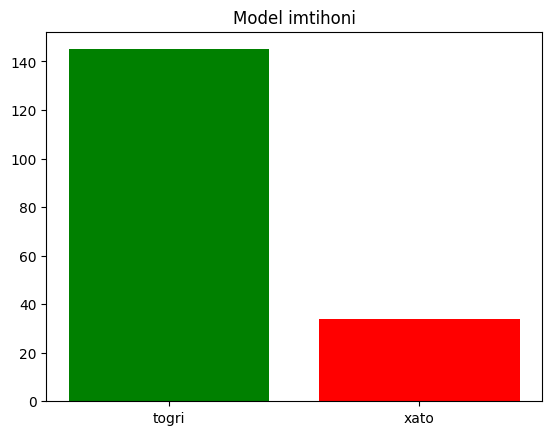

In [ ]:
plt.bar(["correct", "wrong"], [correct, wrong], color=["green", "red"])
plt.title("Model exam")
plt.show()


In [ ]:
passenger = pd.DataFrame({
    "Pclass":      [3],     # ticket class: 1, 2 or 3
    "Sex":         [1],     # 0 = boy, 1 = girl
    "Age":         [12],    # age
    "SibSp":       [0],     # number of siblings traveling together
    "Parch":       [0],     # number of parents traveling together
    "Fare":        [15],    # ticket price
    "Embarked_Q":  [0],
    "Embarked_S":  [1],     # I departed from the Southampton port
})

# Apply the same transformations as the ones used to train the model
passenger["Fare"] = np.log1p(passenger["Fare"])
passenger["FamilySize"] = passenger["SibSp"] + passenger["Parch"] + 1
passenger["IsAlone"] = np.where(passenger["FamilySize"] == 1, 1, 0)
passenger = passenger[X.columns]  # the column order must be the same

probability = model.predict_proba(passenger)[0][1]
print(f"Survival probability: {probability:.0%}")

Survival probability: 72%
